# Bias maps: where does neglecting hyperillumination bias $A_B$ and $F$?

The parameter-space part of `AB_Bias.ipynb` and `F_AB_Bias.ipynb`, without a target planet. The noiseless "data" (Asimov dataset) are a `hyperillum` phase curve with Bond albedo $A_{B,\rm true}$ and no heat redistribution. They are fitted with the point-source models, with the baseline free:
1. **$A_B$ only** (`naive`), as in `AB_Bias.ipynb`.
2. **$A_B$ and $F$ jointly** (`naive_redist`, Kreidberg & Loeb 2016 heat redistribution), as in `F_AB_Bias.ipynb`. The truth has $F = 0$, so the fitted $F$ is itself the bias in $F$.

Each section has a bias map over $(a/R_\star, T_{\rm eff})$ (the $(a/R_\star, R_p/R_\star)$ map is commented out in the same cell), a per-planet decision for the 10 closest-in known rocky planets, and one planet retrieved with several instruments, as the fitted $A_B$ and as the occultation depth of the fit.

The maps are computed at a **reference geometry** set in the setup below, not at any particular planet: the inclination `incl_ref` (a central transit by default, so every cell occults), the fixed $R_p/R_\star$ of the $T_{\rm eff}$ map (`rp_rs_ref`) and the fixed $T_{\rm eff}$ of the $R_p/R_\star$ map (`T_eff_ref`). The period drops out of the bias. The maps do not depend on the noise or the number of orbits; the per-planet decisions do.
With a central transit, the maps **overstate** the bias of planets with a large impact parameter (see the end of 1.2). The per-planet decisions fit every planet at its own geometry and are not affected.

Set `target` to a `PlanetParams` to draw one planet as the green star on every map; by default no planet is highlighted.

In [1]:
import numpy as np
import os
import contextlib, io
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from joblib.externals.loky import get_reusable_executor  # to recycle leaky SPIDERMAN workers
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman as sp
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from astro_utils import *
import batman_utils
from simple_bias_analysis import *
from HItargets_utils import *
from paper_plot_utils import paper_figure, paper_theme

# Exoplanet Archive (to populate bias map)
AGG = os.path.join(os.path.dirname(os.path.abspath('')), 'NASAExoplanetArchive', 'NASAExoArchive_2026-08-21_aggregate_short.csv')

In [2]:
# Reference geometry of the maps. Each map sweeps a/Rs and one more parameter; everything else is held at these values.
incl_ref  = 90.     # [deg] central transit, so every map cell occults
rp_rs_ref = 0.015   # Rp/Rs held fixed on the (a/Rs, T_eff) map (middle of the rp_rs_grid box)
T_eff_ref = 4000.   # [K] T_eff held fixed on the (a/Rs, Rp/Rs) map
ref = reference_planet(rp_rs=rp_rs_ref, T_eff=T_eff_ref, incl=incl_ref)   # a/Rs is swept; period and stellar radius are placeholders the bias does not depend on

# Optional: a planet drawn as the green star on every map (and dropped from the archive scatter), e.g. target = hi_planets_by_name("TOI-2431 b"). None: no planet is highlighted.
target = None

u = [0.15, 0.08]                            # Band-integrated (MIR) quadratic stellar limb darkening coefficients [u1, u2] (placeholders from grey Eddington atmosphere, will be set by theoretical stellar atmosphere models)
u_B = 0.6                                   # Bolometric linear stellar limb darkening coefficient (placeholder, from Sadh_Gavassino_2026)

In [3]:
# Albedo assumptions

# K2-141b Geometric albedo in the optical from Zieba 2022 (using Kepler, Spitzer data are not able to constrain the albedo at 4.5 µm). This is likely an overestimate. Zieba 2022 assumed A_B=A for Kepler.
# Ag = 0.28

# Assuming grey Lambertian reflectance. PROBABLY UNPHYSICAL!
# A_B basically unrelated to A (MIR band integrated), mainly influenced by albedo in optical (lambda_max=630nm) + clouds/atmosphere
# 0.3 seems like a reasonable assumption for TOI-2431b
A_B_true = 0.3 #3/2 * Ag # 0.42

# ASSUMPTION (!)
# Model for band-integrated albedo in the observing band (MIR)
A_model = ConstantBandAlbedo(.1) # Band-integrated albedo of rocky surface fixed to A=0.1 (small reflected part) in MIR
# A_model = ScaledBandAlbedo(1.) # Band-integrated albedo in MIR of rocky surface set to A=A_B (probably overestimate).

In [4]:
# Filter and observation
instrument = "MIRI/LRS" # "JWST_NIRSpec.G395H_NRS1", "MIRI/LRS", "MIRI/F1280W"
filter_path = filter_loc(instrument)
l1, l2 = filter_lambda(instrument)
n_bins = 27     # number of bins in one orbit
n_orbits = 5    # number of orbits observed; enters only the per-planet decisions (the maps are noise-independent)


# sigma_1min is a placeholder for the maps: the bias is the chi^2 minimum, which does not depend on the noise scale. Only the convergence tolerance of the
# joint fit (absolute in chi^2) does, so keep it realistic. The per-planet decisions replace it with each planet's own PandExo noise.
cfg = FittingConfig(planet=ref, filter_path=filter_path,
                    l1=l1, l2=l2, A_=A_model,
                    sigma_1min=100., n_orbits=n_orbits, n_bins=n_bins,
                    reflected=True, u_B=u_B, u=u)

set_plot_style()
geom = rf"$A_B$ = {A_B_true:.2f}, $i$ = {incl_ref:g}°"   # for the figure titles

In [5]:
# Map grids (shared by both sections). With a target, map_grid widens the box so that the target lies on its own map.
a_rs_grid  = map_grid(1.5, 4.0, 20, include=None if target is None else target.R / target.r2)
T_eff_grid = map_grid(3000., 6000., 10, include=None if target is None else target.T2_eff, bounds=(TEFF_NODES[0], TEFF_NODES[-1]))   # T_s stays on the stellar grid's T_eff nodes
rp_rs_grid = map_grid(0.01, 0.025, 10, include=None if target is None else target.r1 / target.r2)
# Panels of the *.1 bias maps: absolute |Delta A_B| and / or relative |Delta A_B| / A_B. (False, True) shows the relative map alone.
show_absolute, show_relative = False, True

kw = dict(n_lo=300, n_la=150)     # n_layers is left to the per-model default of pcurve_params (40 hyperillum, 60 naive / naive_redist)

# Sample for the per-planet decisions (1.2 and 2.2): the 10 smallest-a/Rs rocky planets inside the (a/Rs, Rp/Rs) map box.
# Same sample definition overlay_planets draws on the maps (rocky, Rp < 1.7 R_Earth, inside the map box), so figure and map cannot disagree.
top10 = rocky_sample(AGG, "pl_ratror", (rp_rs_grid[0], rp_rs_grid[-1]), a_rs_lim=(a_rs_grid[0], a_rs_grid[-1])).nsmallest(10, "a_over_r2")
planets10 = hi_planets_by_name(list(top10.pl_name))
# One PandExo run per planet: NOT cached and seconds per target, so keep this dict rather than recomputing it.
sigma10 = rms_1min_pandexo_sample(top10.pl_name, instrument)

Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation


## 1. Bias in $A_B$ (A_B-only fit, `naive`)

### 1.1 In which regimes does hyperillumination matter? Bias map over (a/Rs, T_eff)

Theoretically the period P should be varied with (a/R★) for a fixed ρ★ = 3π(a/R★)³/(GP²). This is not necessary/answer-changing since the period is degenerate in the bias analysis.

non-railed cells: 200 of 200;  Delta A_B in [-0.258, -0.007] = [-86.1, -2.5] % of A_B
railed: 0


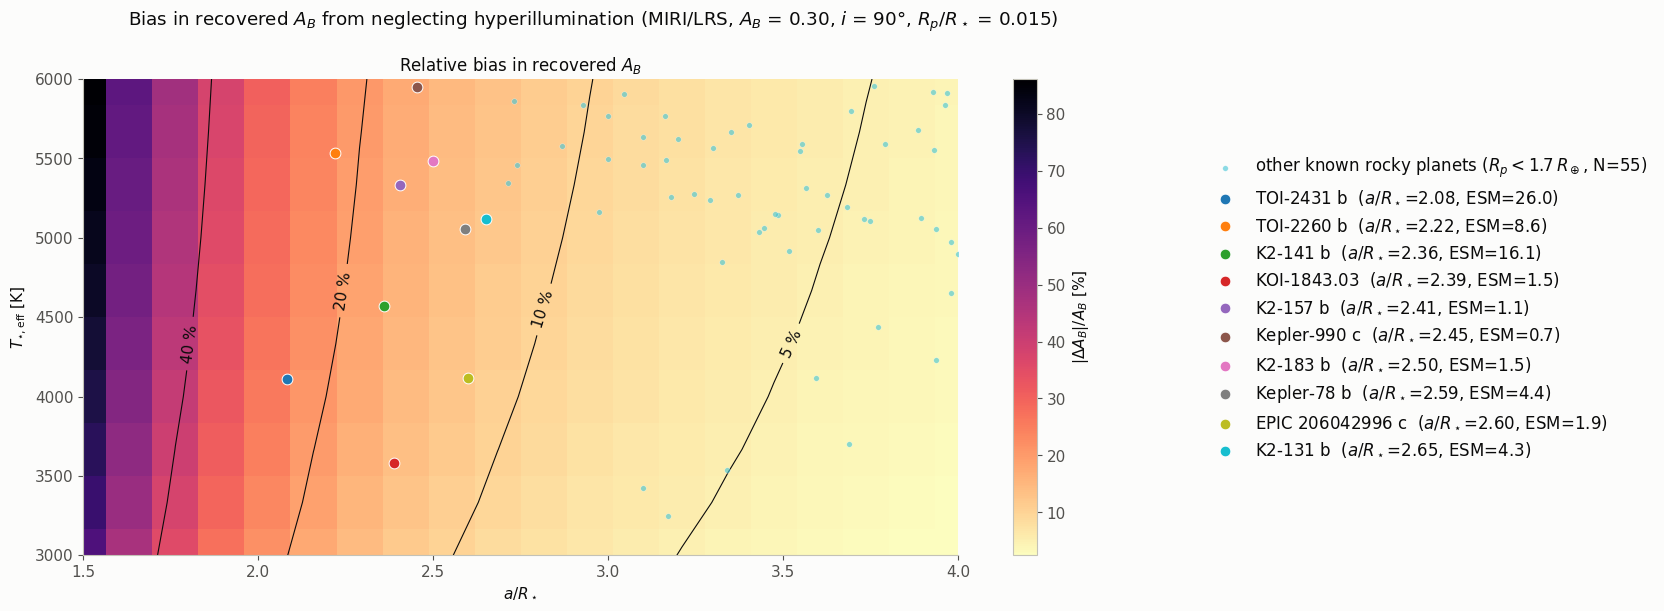

In [6]:
PAPER_MODE = False
# TODO: For careful evaluation of physical parameter space, add Roche limit to map
# The bias in recovered A_B is a pure model-degeneracy quantity, so this map is independent of the noise level sigma. The cells are independent -> run in parallel.
bias_map_T = bias_map_grid(cfg, A_B_true, a_rs_grid, T_eff_grid, "T_s", **kw)
fig, axs = plot_bias_maps(a_rs_grid, T_eff_grid, bias_map_T, A_B_true, AGG, "st_teff", r"$T_{\star,\rm eff}$ [K]",
               rp_rs_of=lambda y: np.full_like(y, rp_rs_ref), incl=incl_ref, target=target, show_absolute=show_absolute, show_relative=show_relative,   # panel switches from the setup
               title=rf"Bias in recovered $A_B$ from neglecting hyperillumination ({instrument}, {geom}, $R_p/R_\star$ = {rp_rs_ref:g})")
paper_figure("biasmap_teff", PAPER_MODE, fig=fig)
plt.show()

# bias_map = bias_map_grid(cfg, A_B_true, a_rs_grid, rp_rs_grid, "rp_rs", **kw)
# plot_bias_maps(a_rs_grid, rp_rs_grid, bias_map, A_B_true, AGG, "pl_ratror", r"$R_p/R_\star$",
#                rp_rs_of=lambda y: y, incl=incl_ref, target=target, show_absolute=show_absolute, show_relative=show_relative,   # panel switches from the setup
#                title=rf"Bias in recovered $A_B$ from neglecting hyperillumination ({instrument}, {geom}, $T_{{\rm eff}}$ = {T_eff_ref:g} K)")

Grey cells mark railed fits, where the naive model cannot reproduce the truth at any albedo; the line under the map counts them and gives the range of $\Delta A_B$. The panels are chosen in the setup (`show_absolute`, `show_relative`): the absolute bias $|\Delta A_B|$, the relative bias $|\Delta A_B|/A_B$, or both; the same switches apply to the joint-fit map of 2.1.

What to look for: the sign of $\Delta A_B$ (an underestimate is the expected hyperillumination signature), how fast $|\Delta A_B|$ falls with $a/R_\star$ (where the 0.05 and 0.02 contours lie), and how the contours move with $T_{\rm eff}$. So far (MIRI/LRS and NIRSpec G395H) the bias has been an underestimate everywhere, growing with $T_{\rm eff}$ at fixed $a/R_\star$.

### 1.2 Per-planet decision: does hyperillumination matter for the closest-in rocky planets?

The 10 smallest-$a/R_\star$ rocky planets inside the map box, each re-fitted with its **own** geometry and its **own** PandExo noise for this instrument, at the same assumed $A_B$.
The bias is noise-independent (it is a pure model-degeneracy quantity), so only the Fisher $\sigma_{A_B}$ moves with the noise and
$\sigma_{1\rm min, crit} = \sigma_{1\rm min}\,|\Delta A_B|/\sigma_{A_B}$ is an identity, not an extrapolation: the per-minute precision at which the bias would be a $1\sigma$ effect.
A planet needs hyperillumination exactly where the delivered $\sigma_{1\rm min}$ is at or below the required $\sigma_{1\rm min, crit}$.

A planet whose Fisher $\sigma_{A_B}$ is at or above the flat-prior std $(hi - lo)/\sqrt{12}$ of the fit bounds (0.289 for $A_B \in [0, 1]$, dashed line) is marked *unconstrained* (hatched bars): there $|\Delta A_B|/\sigma_{A_B}$ is a ratio to a meaningless number, so neither "needs hyperillumination" nor "naive OK" applies. A Gaussian as wide as the prior std carries no information relative to the box ($H = \ln[(hi-lo)/(\sigma\sqrt{2\pi e})] \approx -0.2$ nats; its truncated posterior is the prior, and dynesty returns exactly the prior std there).


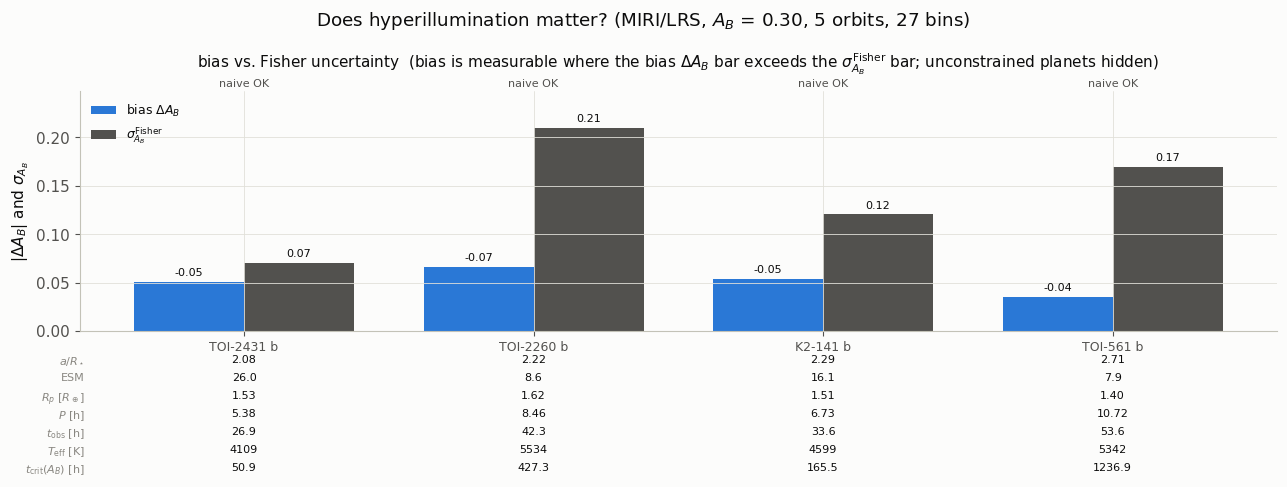

0 of 10 needs hyperillum: -
4 of 10 naive OK: TOI-2431 b, TOI-2260 b, K2-141 b, TOI-561 b
6 of 10 unconstrained: KOI-1843.03, Kepler-990 c, K2-183 b, Kepler-78 b, EPIC 206042996 c, K2-131 b
            name  a_rs    esm     bias   sigma  bias_sigma  sigma_1min  sigma_1min_crit       verdict
      TOI-2431 b 2.081  25.96 -0.05115 0.07039      0.7267        91.9            66.79      naive OK
      TOI-2260 b 2.219  8.632 -0.06613  0.2102      0.3146         182            57.25      naive OK
        K2-141 b 2.292  16.12 -0.05434  0.1205      0.4509       154.5            69.67      naive OK
     KOI-1843.03 2.389   1.47 -0.02113   2.649    0.007977       868.8            6.931 unconstrained
    Kepler-990 c 2.453 0.6968 -0.04478   8.685    0.005156        6360            32.79 unconstrained
        K2-183 b   2.5  1.483 -0.04558   2.064     0.02208        1133            25.01 unconstrained
     Kepler-78 b 2.592  4.415 -0.02255  0.4321     0.05219       350.4            18.29 unconstr

In [7]:
PAPER_MODE = False
tab_AB = planet_bias_table(cfg, A_B_true, planets10, sigma10, AGG=AGG, **kw)   # cfg supplies filter / stellar grid / albedo model / n_bins / n_orbits; geometry and sigma_1min are per planet; AGG supplies the ESM / Rp rows
fig, ax = plot_planet_bias_bars(tab_AB, bias_break=(0.32, 0.4), title=f"Does hyperillumination matter? ({instrument}, $A_B$ = {A_B_true:.2f}, {cfg.n_orbits} orbits, {cfg.n_bins} bins)")   # bias_break: linear axis broken between 0.32 and 0.4 (above the flat-prior line, below the smallest unconstrained sigma), so the unconstrained sigmas do not flatten the measurable ones
paper_figure("biasbars_planets_AB", PAPER_MODE, fig=fig)
plt.show()

# Three-way verdict (bias_verdict): bias >= 1 sigma needs hyperillumination; below it naive is OK only where sigma_A_B is below the flat-prior std of the fit bounds, otherwise A_B is simply unconstrained.
for v in (VERDICT_NEEDS_HI, VERDICT_NAIVE_OK, VERDICT_UNCONSTRAINED):
    sel = tab_AB[tab_AB.verdict == v]
    print(f"{len(sel)} of {len(tab_AB)} {v}: {', '.join(sel.name) if len(sel) else '-'}")
print(tab_AB[["name", "a_rs", "esm", "bias", "sigma", "bias_sigma", "sigma_1min", "sigma_1min_crit", "verdict"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"))

The verdicts and the table above are the result: a planet needs hyperillumination where `bias_sigma` $\ge 1$, i.e. where the delivered $\sigma_{1\rm min}$ is at or below $\sigma_{1\rm min, crit}$. Planets whose PandExo noise is too high to measure $A_B$ at all come out *unconstrained*.

**The maps overstate the bias of inclined planets.** The bar plots fit every planet at its own geometry, while the maps assume the reference inclination `incl_ref`. The table below reads each planet's bias off the $(a/R_\star, T_{\rm eff})$ map of 1.1 at its position and compares it with its own-geometry fit (`map_excess` > 0: the map overstates).
Planets with a large impact parameter $b = (a/R_\star)\cos i$ come out too large on the map, while for $b \approx 0$ the two agree closely. Re-fitting a planet at its own $a/R_\star$, $R_p/R_\star$ and $T_{\rm eff}$ but $i = 90°$ reproduces the map value (checked for the 10 planets with MIRI/LRS, $A_B = 0.3$: the $i = 90°$ refit and the map value agree to better than 0.001), so the difference is almost entirely the inclination; the map's fixed $R_p/R_\star$ hardly contributes. Reading planets off the $(a/R_\star, R_p/R_\star)$ map instead adds the fixed `T_eff_ref` as a second error, largest for the hottest stars.
For scale, lowering the reference inclination to 74° shrinks the whole map by about half (median $|\Delta A_B|$ $-47\,\%$ in the cells that still occult; $(a/R_\star, T_{\rm eff})$ map, MIRI/LRS, $A_B = 0.3$, $R_p/R_\star = 0.015$) and removes the occultation beyond $a/R_\star \approx 3.7$.
The verdicts above are not affected, because they use the own-geometry fit.

### 1.3 One planet, several instruments: retrieved $A_B$
After Ramirez et al. 2026 (arXiv:2610.22338), Fig. 4. For one planet (`retrieval_planet`), the hyperillumination truth with Bond albedo `A_B_inj` is fitted with the $A_B$-only model on each instrument of `retrieval_instruments`. Each point is the fitted $A_B$, with the Fisher $1\sigma$ (dark) and $2\sigma$ (light) error bars; the dashed line is the injected value. Each instrument uses the planet's own geometry and noise level: PandExo where it has a mode, otherwise the planet's entry in `CUSTOM_SIGMA_1MIN` (`HItargets_utils.py`). Instruments with neither are left out with a note. An entry given as a tuple of detectors, here the two NIRSpec/G395H arrays, is one **joint fit** of those detectors: one shared $A_B$, a separate baseline offset per detector, and the $\chi^2$ summed over both arrays. It gets its own position in the plot (NaN as `sigma_1min` in the table; the per-detector noise levels are in `tab.attrs["sigma_1min"]`). A hollow marker means the fit is *unconstrained* (Fisher $\sigma$ at or above the flat-prior std), so its error bar does not measure anything.

What to look for: whether the injected value lies inside the $1\sigma$ / $2\sigma$ bars. The offset of each point from the dashed line is that instrument's bias. It changes with the band, because the share of reflected and thermal light and the hyperillumination signal depend on wavelength. The bar width scales with each instrument's noise level. The joint NRS1 + NRS2 point should land between the two single-array points with a narrower bar, since the two arrays constrain the same $A_B$.

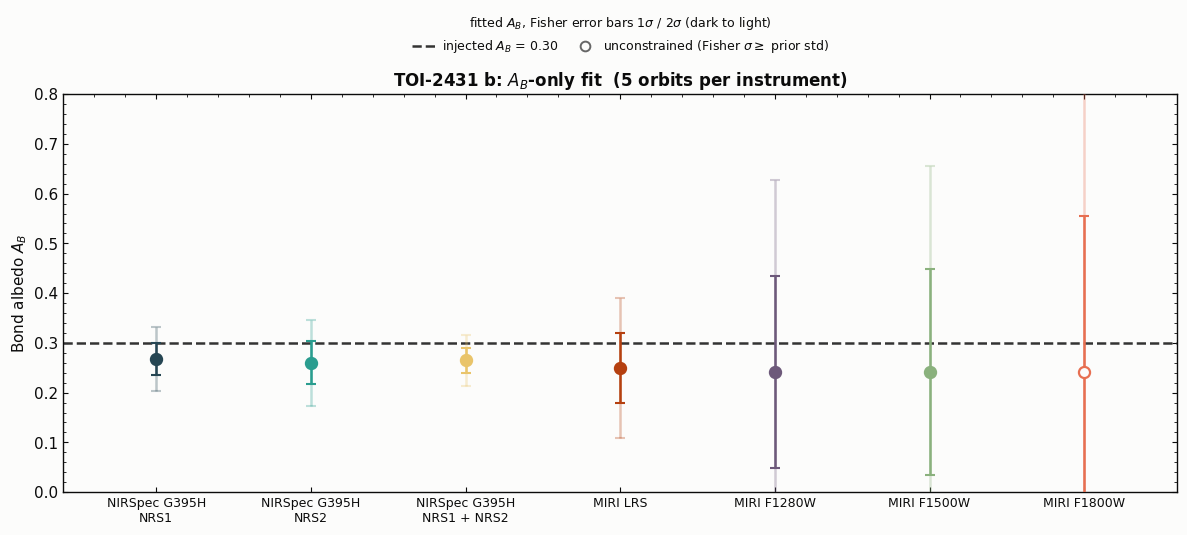

                                     instrument  sigma_1min  A_B_fit  bias_A_B  sigma_A_B  bias_sigma          verdict
                        JWST_NIRSpec.G395H_NRS1       39.24   0.2677  -0.03232     0.0319       1.013 needs hyperillum
                        JWST_NIRSpec.G395H_NRS2        56.2   0.2598  -0.04023    0.04314      0.9325         naive OK
JWST_NIRSpec.G395H_NRS1+JWST_NIRSpec.G395H_NRS2           -   0.2649  -0.03514    0.02565        1.37 needs hyperillum
                                       MIRI/LRS        91.9   0.2488  -0.05115    0.07039      0.7267         naive OK
                                    MIRI/F1280W       247.2    0.242  -0.05804      0.193      0.3007         naive OK
                                    MIRI/F1500W         264   0.2415  -0.05851     0.2073      0.2822         naive OK
                                    MIRI/F1800W       396.2   0.2413  -0.05868     0.3131      0.1875    unconstrained


In [8]:
PAPER_MODE = False
# One planet on several instruments: fitted A_B +- Fisher sigma per instrument, for a hyperillumination truth injected at A_B_inj.
retrieval_planet = hi_planets_by_name("TOI-2431 b")
retrieval_instruments = ["JWST_NIRSpec.G395H_NRS1", "JWST_NIRSpec.G395H_NRS2",   # sorted by wavelength: the plots of 1.3, 1.4, 2.3, 2.4 and 2.6 keep this order
                         ("JWST_NIRSpec.G395H_NRS1", "JWST_NIRSpec.G395H_NRS2"),   # a tuple = one joint fit of these detectors (shared A_B, a baseline per detector)
                         "MIRI/LRS", "MIRI/F1280W", "MIRI/F1500W", "MIRI/F1800W"]
A_B_inj = A_B_true   # injected Bond albedo; n_orbits and the band albedo model come from cfg

tab_inst_AB = instrument_retrievals(cfg, retrieval_planet, retrieval_instruments, A_B_inj, **kw)
sigma_inst = tab_inst_AB.attrs["sigma_1min"]   # {detector: ppm/min}; PandExo is not cached: 2.3 reuses these noise levels
fig, ax = plot_instrument_retrievals(tab_inst_AB, title=f"{retrieval_planet.name}: $A_B$-only fit  ({cfg.n_orbits} orbits per instrument)")
paper_figure(f"retrieval_instruments_AB_{retrieval_planet.name.replace(' ', '')}", PAPER_MODE, fig=fig)
plt.show()
print(tab_inst_AB.drop(columns=["F_fit", "sigma_F"]).to_string(index=False, na_rep="-", float_format=lambda v: f"{v:.4g}"))

### 1.4 One planet, several instruments: occultation depth of the fit
The fits of 1.3 seen through the observable instead of the parameter: for each instrument, the occultation depth $\delta$ of the fitted $A_B$-only model next to the depth of the hyperillumination truth. No refit: the fitted parameters of 1.3 are reused, so run 1.3 first.

Both depths are evaluated exactly at mid-occultation (`model_depth`): the thermal part with `occultation_depth()` on the fitted SPIDERMAN model (unblocked minus blocked flux at the occultation time), the reflected part as the planet's reflected flux at full phase. This is not the phase-curve height just before ingress, which on these short-period planets sits well below the depth because the phase still changes over the long occultation. The depth uses more SPIDERMAN layers than the fit (`DEPTH_N_LAYERS`), since the naive depth converges only slowly with `n_layers`.

Each point is the fitted depth $\delta_{\rm fit}$; the true depth differs between bands, so each instrument has its own dashed segment at $\delta_{\rm true}$. The error bars are the depth's Fisher $1\sigma$ / $2\sigma$, propagated from the fit's parameter covariance ($\sigma_\delta^2 = \nabla\delta^{\mathsf T} C\, \nabla\delta$). A hollow marker means the fit is unconstrained in $A_B$, as in 1.3. The joint NRS1 + NRS2 fit of 1.3 is left out here: the depth is a per-band quantity, so a two-array fit has no single depth.

What to look for: whether the fitted depth stays within its error bar of the truth while $A_B$ (1.3) is biased. If it does, the eclipse alone gives no sign that the model is misspecified.

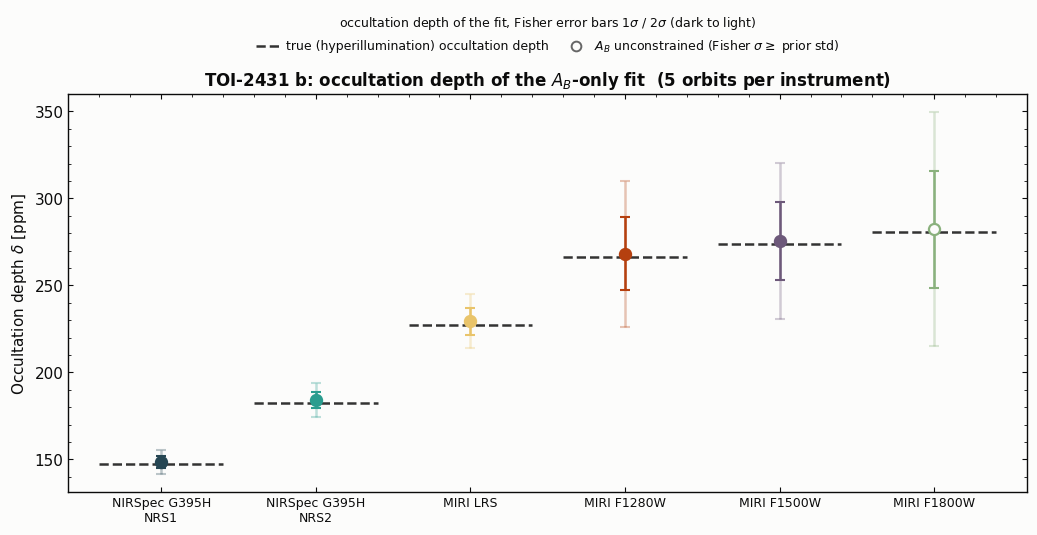

             instrument  A_B_fit  depth_true  depth_fit  bias_depth  sigma_depth  depth_bias_sigma  bias_sigma          verdict
JWST_NIRSpec.G395H_NRS1   0.2677       147.3      148.4       1.144        3.385             0.338       1.013 needs hyperillum
JWST_NIRSpec.G395H_NRS2   0.2598       182.6      184.1       1.575        4.817            0.3269      0.9325         naive OK
               MIRI/LRS   0.2488       227.5      229.4       1.923        7.828            0.2456      0.7267         naive OK
            MIRI/F1280W    0.242       266.3      268.1       1.794        20.98            0.0855      0.3007         naive OK
            MIRI/F1500W   0.2415       273.7      275.4       1.656        22.39           0.07396      0.2822         naive OK
            MIRI/F1800W   0.2413       280.9      282.4       1.491        33.59           0.04438      0.1875    unconstrained


In [9]:
PAPER_MODE = False
# Occultation depth of each A_B-only fit of 1.3 (no refit), exact at mid-occultation, against the true hyperillumination depth on the same instrument.
tab_depth_AB = instrument_depths(cfg, retrieval_planet, tab_inst_AB, **kw)   # same cfg / planet / kw as the fits of 1.3
fig, ax = plot_instrument_retrievals(tab_depth_AB, quantity="depth", title=f"{retrieval_planet.name}: occultation depth of the $A_B$-only fit  ({cfg.n_orbits} orbits per instrument)")
paper_figure(f"retrieval_instruments_depth_{retrieval_planet.name.replace(' ', '')}", PAPER_MODE, fig=fig)
plt.show()
depth_cols = ["instrument", "A_B_fit", "F_fit", "depth_true", "depth_fit", "bias_depth", "sigma_depth", "depth_bias_sigma", "bias_sigma", "verdict"]   # bias_sigma / verdict: those of A_B, for comparison
print(tab_depth_AB[[c for c in depth_cols if c != "F_fit"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"))

## 2. Joint bias in $A_B$ and $F$ (`naive_redist`)

The same maps for the joint fit of $A_B$, $F$ and the baseline. The truth has $F = 0$, so the fitted $F$ is the bias in $F$: heat redistribution that the data do not contain. $F$ is bounded to $[0, 0.5]$, and $F = 0$ is a valid fit.
With an inclination below 90°, cells whose impact parameter $b = (a/R_\star)\cos i$ reaches $1 + R_p/R_\star$ have no occultation and are greyed out: without the eclipse nothing anchors the flux level, and $A_B$ and $F$ become degenerate. The dashed lines then bound the grazing zone. With a central transit every cell occults, so neither appears.

### 2.1 In which regimes does hyperillumination matter? Bias maps over (a/Rs, T_eff)

occulting, non-railed cells: 186 of 200;  Delta A_B in [-0.293, -0.025] = [-97.6, -8.5] % of A_B,  F in [0.0017, 0.0130]
railed: 14,  without occultation: 0


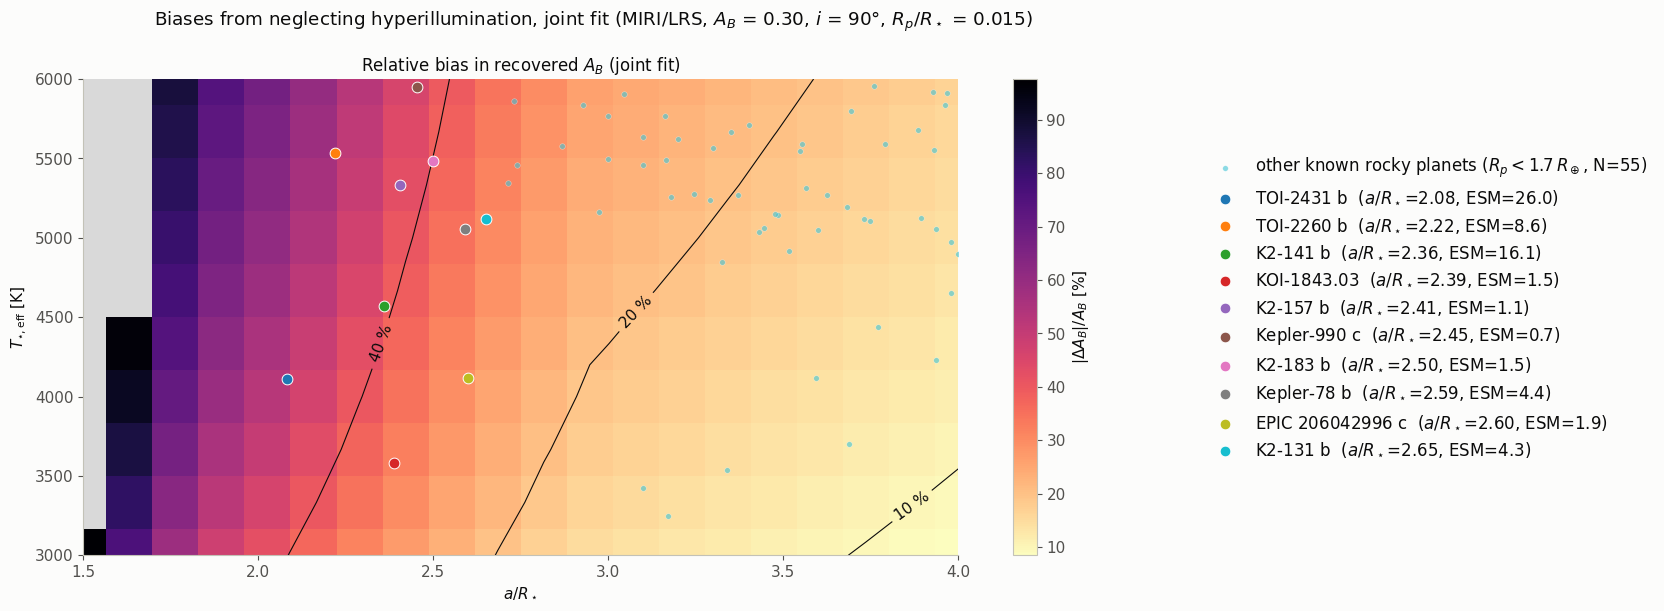

In [10]:
PAPER_MODE = False
# TODO: For careful evaluation of physical parameter space, add Roche limit to map
# The biases are pure model-degeneracy quantities, so these maps are independent of the noise level sigma. The cells are independent -> run in parallel.
bias_map_JT, F_map_JT = bias_map_grid(cfg, A_B_true, a_rs_grid, T_eff_grid, "T_s", redist=True, **kw)
fig, axs = plot_bias_maps(a_rs_grid, T_eff_grid, bias_map_JT, A_B_true, AGG, "st_teff", r"$T_{\star,\rm eff}$ [K]",
               rp_rs_of=lambda y: np.full_like(y, rp_rs_ref), incl=incl_ref, F_map=F_map_JT, target=target,
               show_absolute=show_absolute, show_relative=show_relative, show_F=False,   # panel switches from the setup; show_F=True adds the fitted-F panel
               title=rf"Biases from neglecting hyperillumination, joint fit ({instrument}, {geom}, $R_p/R_\star$ = {rp_rs_ref:g})")
paper_figure("biasmap_teff_joint", PAPER_MODE, fig=fig)
plt.show()

# bias_map, F_map = bias_map_grid(cfg, A_B_true, a_rs_grid, rp_rs_grid, "rp_rs", redist=True, **kw)
# plot_bias_maps(a_rs_grid, rp_rs_grid, bias_map, A_B_true, AGG, "pl_ratror", r"$R_p/R_\star$",
#                rp_rs_of=lambda y: y, incl=incl_ref, F_map=F_map, target=target,
#                show_absolute=show_absolute, show_relative=show_relative, show_F=False,   # panel switches from the setup; show_F=True adds the fitted-F panel
#                title=rf"Biases from neglecting hyperillumination, joint fit ({instrument}, {geom}, $T_{{\rm eff}}$ = {T_eff_ref:g} K)")

The line under the map gives the range of $\Delta A_B$ and of the fitted $F$; `show_F=True` adds the $F$ map.

What to look for: how much larger the joint bias is than the $A_B$-only bias of 1.1, and whether the fitted $F$ is non-zero everywhere. Freeing $F$ lets the fit trade albedo for a spurious nightside: the fit lowers $A_B$ and adds a small $F$. So far (MIRI/LRS, $A_B = 0.3$) $F > 0$ in every cell ($F$ between 0.002 and 0.013), and the joint map has the same smooth shape as 1.1, scaled up by a factor of roughly 2–3 (median 2.5, range 1.5–4 over the map).
The joint fit profiles out $A_B$ and scans $F$ (`fit_redist`). A local optimizer started at $F = 0$ gets stuck on that bound, because the nightside switches on extremely flatly with $F$ ($T_{\rm night} \propto F^{1/4}$). That is what produced the earlier step in this map.

### 2.2 Per-planet decision: does the biased $A_B$ (and the spurious $F$) matter for the closest-in rocky planets?

The 10 smallest-$a/R_\star$ rocky planets inside the map box, each re-fitted with its **own** geometry and its **own** PandExo noise for this instrument, at the same assumed $A_B$.
The truth has $F = 0$, so the fitted $F$ **is** the bias: a non-zero value is heat redistribution that the data do not contain, i.e. hyperillumination masquerading as an atmosphere.
The decision columns (`bias`, `sigma`, `bias_sigma`, `sigma_1min_crit`) refer to $A_B$ by default; pass `quantity="F"` to `planet_bias_table` to put them on the spurious $F$ instead.
$\sigma_{1\rm min, crit} = \sigma_{1\rm min}\,|{\rm bias}|/\sigma$ is then the precision at which that bias would be reported as a $1\sigma$ effect -- and the planets where the delivered precision already beats it are the ones where a naive fit would report an albedo (or a redistribution) that is not there.

A planet whose Fisher $\sigma$ is at or above the flat-prior std $(hi - lo)/\sqrt{12}$ of the fit bounds (0.289 for $A_B \in [0, 1]$, dashed line; 0.144 for $F \in [0, 0.5]$) is marked *unconstrained* (hatched bars): there ${\rm bias}/\sigma$ is a ratio to a meaningless number, so neither "needs hyperillumination" nor "naive OK" applies. A Gaussian as wide as the prior std carries no information relative to the box ($H = \ln[(hi-lo)/(\sigma\sqrt{2\pi e})] \approx -0.2$ nats; its truncated posterior is the prior, and dynesty returns exactly the prior std there).


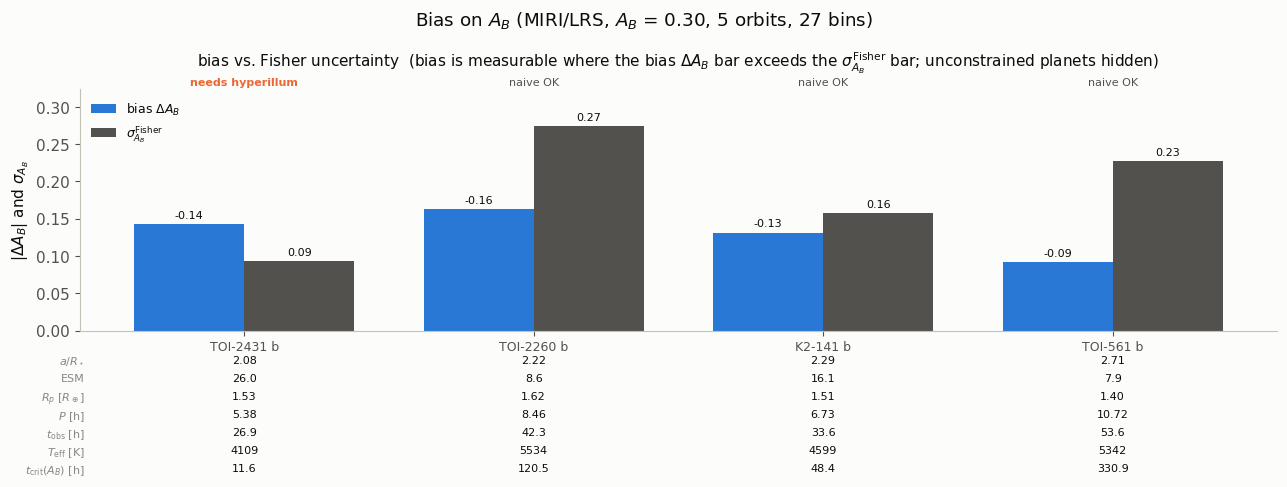

1 of 10 needs hyperillum: TOI-2431 b
3 of 10 naive OK: TOI-2260 b, K2-141 b, TOI-561 b
6 of 10 unconstrained: KOI-1843.03, Kepler-990 c, K2-183 b, Kepler-78 b, EPIC 206042996 c, K2-131 b
            name  a_rs    esm  bias_A_B  sigma_A_B    F_fit  sigma_F  bias_sigma  sigma_1min  sigma_1min_crit          verdict
      TOI-2431 b 2.081  25.96   -0.1422    0.09321 0.005978 0.003889       1.526        91.9            140.2 needs hyperillum
      TOI-2260 b 2.219  8.632   -0.1623     0.2739 0.003227 0.006077      0.5926         182            107.8         naive OK
        K2-141 b 2.292  16.12   -0.1314     0.1576 0.004099 0.005275      0.8336       154.5            128.8         naive OK
     KOI-1843.03 2.389   1.47  -0.08934      3.955  0.00678    0.269     0.02259       868.8            19.62    unconstrained
    Kepler-990 c 2.453 0.6968   -0.1277      11.69 0.002602   0.2571     0.01092        6360            69.47    unconstrained
        K2-183 b   2.5  1.483     -0.12      2.758 

In [11]:
PAPER_MODE = False
# redist=True -> the joint (A_B, F) fit; quantity defaults to "A_B", so bias / sigma / bias_sigma / sigma_1min_crit all refer to the albedo bias (pass quantity="F" for the spurious redistribution instead).
tab_redist = planet_bias_table(cfg, A_B_true, planets10, sigma10, redist=True, AGG=AGG, **kw)
title_tail = f"({instrument}, $A_B$ = {A_B_true:.2f}, {cfg.n_orbits} orbits, {cfg.n_bins} bins)"
fig, ax = plot_planet_bias_bars(tab_redist, bias_break=(0.32, 0.4), quantities=("A_B",), grid=False, title=f"Bias on $A_B$ {title_tail}")   # bias_break: linear axis broken between 0.32 and 0.4 (above the flat-prior line, below the smallest unconstrained sigma), so the unconstrained sigmas do not flatten the measurable ones
paper_figure("biasbars_planets_joint", PAPER_MODE, fig=fig)
plt.show()
# fig, ax = plot_planet_bias_bars(tab_redist, quantities=("F",), grid=False, title=f"Bias on F {title_tail}")
# plt.show()

# Three-way verdict (bias_verdict): bias >= 1 sigma needs hyperillumination; below it naive is OK only where sigma_A_B is below the flat-prior std of the fit bounds, otherwise A_B is simply unconstrained.
for v in (VERDICT_NEEDS_HI, VERDICT_NAIVE_OK, VERDICT_UNCONSTRAINED):
    sel = tab_redist[tab_redist.verdict == v]
    print(f"{len(sel)} of {len(tab_redist)} {v}: {', '.join(sel.name) if len(sel) else '-'}")
print(tab_redist[["name", "a_rs", "esm", "bias_A_B", "sigma_A_B", "F_fit", "sigma_F", "bias_sigma", "sigma_1min", "sigma_1min_crit", "verdict"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"))

The verdicts and the table above are the result. Compare with 1.2: the joint $A_B$ bias is larger than the $A_B$-only bias for every planet, and the fit attributes part of the misfit to a spurious $F$. That can push a planet from *naive OK* to *needs hyperillumination*, although the Fisher $\sigma_{A_B}$ grows as well because of the $A_B$–$F$ degeneracy. The *unconstrained* planets stay unconstrained.
As in 1.2, the table below reads each planet's joint bias off the $(a/R_\star, T_{\rm eff})$ map of 2.1. Planets with a large impact parameter come out too large on the map; for $b \approx 0$ the map and the own-geometry fit agree closely.

The same per-planet result in the figure style of 2.3: the fitted $A_B$ itself (not the bias) with its Fisher $1\sigma$ / $2\sigma$ bars, the joint fit (squares) next to the $A_B$-only fit of 1.2 (circles), one position per planet. The dashed line is the assumed $A_B$. The planets that the joint fit leaves *unconstrained* (hatched in the bars above) are dropped: their bars would only be the prior width.

What to look for: the same as in the bar plot, read the other way round -- whether the assumed $A_B$ lies inside each planet's bars, and how far freeing $F$ pulls the squares below the circles.

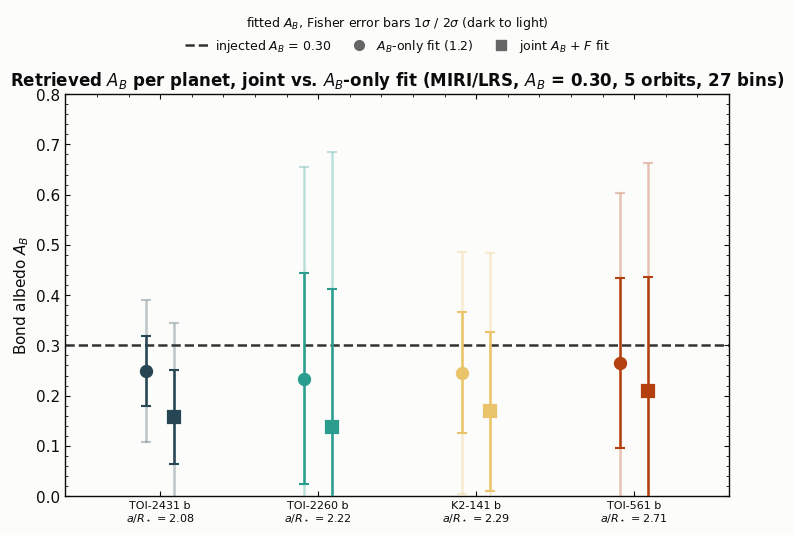

dropped (unconstrained in the joint fit): KOI-1843.03, Kepler-990 c, K2-183 b, Kepler-78 b, EPIC 206042996 c, K2-131 b


In [12]:
PAPER_MODE = False
# 2.2 as a retrieval plot (plot_instrument_retrievals with xcol="name": one position per planet, on this instrument): the joint fit of this section next to the A_B-only fit of 1.2,
# without the planets the joint fit leaves unconstrained (drop_unconstrained with like=tab_redist keeps the same planets in both tables).
fig, ax = plot_instrument_retrievals({"$A_B$-only fit (1.2)": drop_unconstrained(tab_AB, like=tab_redist), "joint $A_B$ + $F$ fit": drop_unconstrained(tab_redist)}, xcol="name",
                                     title=f"Retrieved $A_B$ per planet, joint vs. $A_B$-only fit {title_tail}")
paper_figure("retrieval_planets_joint_vs_AB", PAPER_MODE, fig=fig)
plt.show()
print(f"dropped (unconstrained in the joint fit): {', '.join(tab_redist.loc[tab_redist.verdict == VERDICT_UNCONSTRAINED, 'name']) or '-'}")

### 2.3 One planet, several instruments: retrieved $A_B$ with the joint fit
The same as 1.3 for the joint $A_B$ + $F$ fit (squares), next to the $A_B$-only fit of 1.3 (circles), as the paper's figure sets two fits side by side. It reuses the planet, instruments, injected $A_B$ and noise levels of 1.3, so run 1.3 first. The table also lists the spurious $F$ and its Fisher $\sigma$ per instrument. The joint NRS1 + NRS2 fit shares $A_B$ and $F$ between the arrays, with a baseline per array.

What to look for: how far freeing $F$ moves each instrument's point away from the dashed line, and whether the joint bars still reach the injected value.

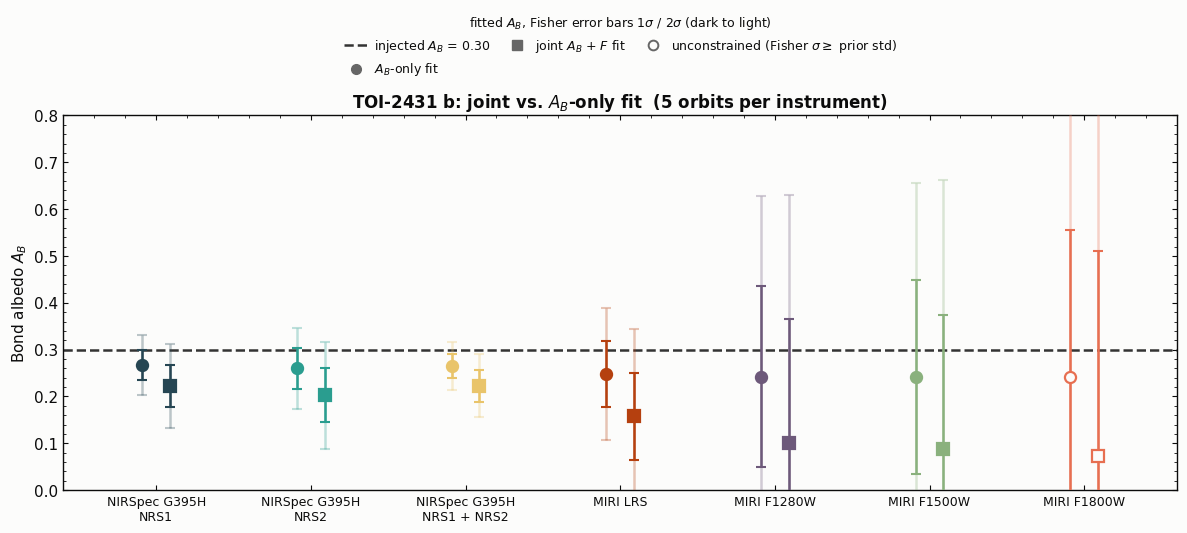

                                     instrument  sigma_1min  A_B_fit  bias_A_B  sigma_A_B    F_fit  sigma_F  bias_sigma          verdict
                        JWST_NIRSpec.G395H_NRS1       39.24   0.2222  -0.07781    0.04448  0.02005  0.01032       1.749 needs hyperillum
                        JWST_NIRSpec.G395H_NRS2        56.2   0.2026  -0.09736    0.05729  0.01321 0.006996       1.699 needs hyperillum
JWST_NIRSpec.G395H_NRS1+JWST_NIRSpec.G395H_NRS2           -   0.2228   -0.0772    0.03361  0.01471  0.00594       2.297 needs hyperillum
                                       MIRI/LRS        91.9   0.1578   -0.1422    0.09321 0.005978 0.003889       1.526 needs hyperillum
                                    MIRI/F1280W       247.2   0.1014   -0.1986     0.2644 0.002576 0.003713      0.7514         naive OK
                                    MIRI/F1500W         264  0.08771   -0.2123     0.2869 0.002045 0.003078        0.74         naive OK
                                    MIRI/

In [13]:
PAPER_MODE = False
# The joint (A_B, F) fit per instrument, set next to the A_B-only fit of 1.3 (same planet, instruments, injected A_B and noise levels).
tab_inst_J = instrument_retrievals(cfg, retrieval_planet, retrieval_instruments, A_B_inj, redist=True, sigma_1min=sigma_inst, **kw)
fig, ax = plot_instrument_retrievals({"$A_B$-only fit": tab_inst_AB, "joint $A_B$ + $F$ fit": tab_inst_J},
                                     title=f"{retrieval_planet.name}: joint vs. $A_B$-only fit  ({cfg.n_orbits} orbits per instrument)")
paper_figure(f"retrieval_instruments_joint_vs_AB_{retrieval_planet.name.replace(' ', '')}", PAPER_MODE, fig=fig)
plt.show()
print(tab_inst_J.to_string(index=False, na_rep="-", float_format=lambda v: f"{v:.4g}"))

### 2.4 One planet, several instruments: occultation depth of the joint fit
The same as 1.4 for the joint $A_B$ + $F$ fits of 2.3 (squares), next to the $A_B$-only fits (circles). It reuses the tables of 1.3, 1.4 and 2.3, so run those first. The depth's Fisher $\sigma$ now includes the $A_B$–$F$ correlation of the joint covariance. As in 1.4, the joint NRS1 + NRS2 fits are left out.

What to look for: whether freeing $F$ moves the fitted depth away from the truth, or whether the joint fit trades a larger $A_B$ bias for the same depth. Compare the depth offsets in units of their $\sigma$ (`depth_bias_sigma`) with the $A_B$ ones (`bias_sigma`).

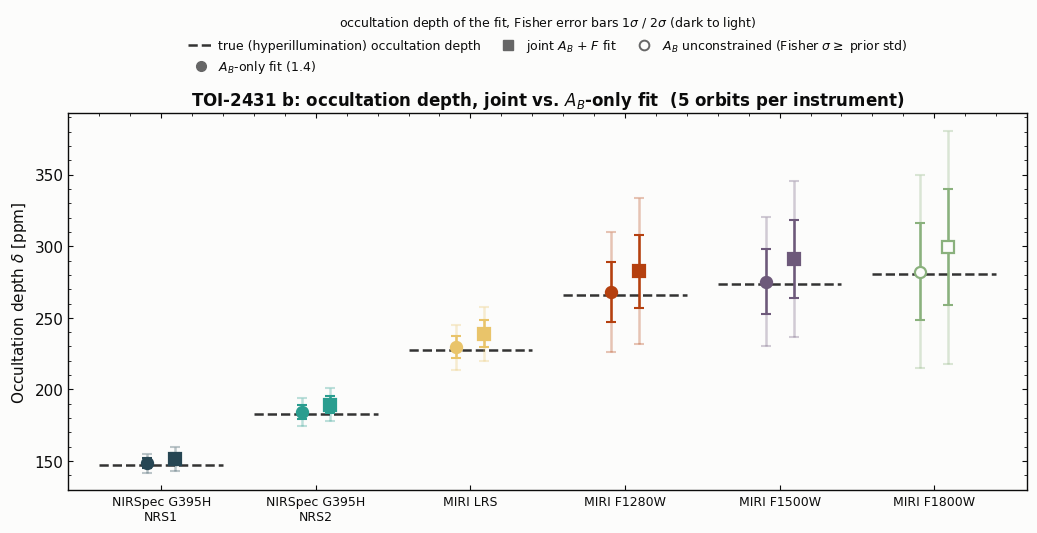

             instrument  A_B_fit    F_fit  depth_true  depth_fit  bias_depth  sigma_depth  depth_bias_sigma  bias_sigma          verdict
JWST_NIRSpec.G395H_NRS1   0.2222  0.02005       147.3      151.4       4.188        4.041             1.036       1.749 needs hyperillum
JWST_NIRSpec.G395H_NRS2   0.2026  0.01321       182.6      189.3       6.739        5.793             1.163       1.699 needs hyperillum
               MIRI/LRS   0.1578 0.005978       227.5      238.9       11.38        9.465             1.202       1.526 needs hyperillum
            MIRI/F1280W   0.1014 0.002576       266.3      282.6       16.33        25.42            0.6423      0.7514         naive OK
            MIRI/F1500W  0.08771 0.002045       273.7      291.1       17.42        27.14             0.642        0.74         naive OK
            MIRI/F1800W  0.07365 0.001603       280.9      299.4       18.52        40.73            0.4547      0.5169    unconstrained


In [14]:
PAPER_MODE = False
# Occultation depth of each joint fit of 2.3 (no refit), set next to the A_B-only depths of 1.4.
tab_depth_J = instrument_depths(cfg, retrieval_planet, tab_inst_J, **kw)
fig, ax = plot_instrument_retrievals({"$A_B$-only fit (1.4)": tab_depth_AB, "joint $A_B$ + $F$ fit": tab_depth_J}, quantity="depth",
                                     title=f"{retrieval_planet.name}: occultation depth, joint vs. $A_B$-only fit  ({cfg.n_orbits} orbits per instrument)")
paper_figure(f"retrieval_instruments_depth_joint_vs_AB_{retrieval_planet.name.replace(' ', '')}", PAPER_MODE, fig=fig)
plt.show()
print(tab_depth_J[depth_cols].to_string(index=False, float_format=lambda v: f"{v:.4g}"))

### 2.5 Where does the spurious $F$ become a false-positive atmosphere? Critical noise map over (a/Rs, T_eff)
The joint fit returns $F > 0$ everywhere on the 2.1 map although the truth has no heat redistribution. An observer who finds $F > 0$ *significantly* would report heat transport, i.e. an atmosphere. How significant the spurious $F$ is, is measured by the likelihood ratio of the two fits of this notebook,
$$\Delta\chi^2_F = \chi^2(A_B\text{-only fit}) - \chi^2(\text{joint } A_B + F \text{ fit}),$$
both at their best fit with a free baseline, on the noiseless truth. $\sqrt{\Delta\chi^2_F}$ is then the median expected one-sided significance of "$F > 0$" (Asimov data set, Cowan et al. 2011). It is exact for the nonlinear $T \propto F^{1/4}$ response and for the boundary at $F = 0$, which is why it is used instead of $F/\sigma_F$: the Fisher $\sigma_F$ is the local slope at $F_{\rm fit}$, but the model responds $\propto F^{1.5}$ near zero, so extrapolating to $F = 0$ overstates the significance, and the boundary is ignored.

$\Delta\chi^2_F$ scales exactly as $n_{\rm orbits}/\sigma_{1\,\rm min}^2$ (the fits themselves do not depend on the noise scale), so the map does not show $\Delta\chi^2_F$ at the placeholder noise but the **critical noise** $\sigma_{1\,\rm min,\,crit} = \sigma_{1\,\rm min}\sqrt{\Delta\chi^2_F}/z$: the per-minute precision at which the spurious $F$ is a $z\sigma$ detection with the notebook's `n_orbits`. A planet observed with better precision than that gets the false positive. The map holds $R_p/R_\star$ and $i$ at the reference values; the signal is $\propto (R_p/R_\star)^2$, so $\sigma_{\rm crit} \propto (R_p/R_\star)^2$, and a planet's own noise level should be compared with the map only after that rescaling (or fitted at its own geometry, as in 2.2).

What to look for: the critical noise rises towards small $a/R_\star$ and hot stars, where the hyperillumination signal that the fit mistakes for redistribution is largest. Compare the contour values with the PandExo noise levels of 1.2/2.2 (`sigma10`, tens to a few hundred ppm/min) to see which part of the map is within reach of a single JWST programme. The printed line also gives the significance range at the placeholder noise, and the fitted-$F$ map is checked against the one of 2.1.

occulting, non-railed cells: 186 of 200;  sigma_1min,crit (2 sigma, 5 orbits) in [3.7, 122.4] ppm/min;  sqrt(dchi2_F) at sigma_1min = 100 ppm/min in [0.07, 2.45] sigma
railed: 14,  without occultation: 0


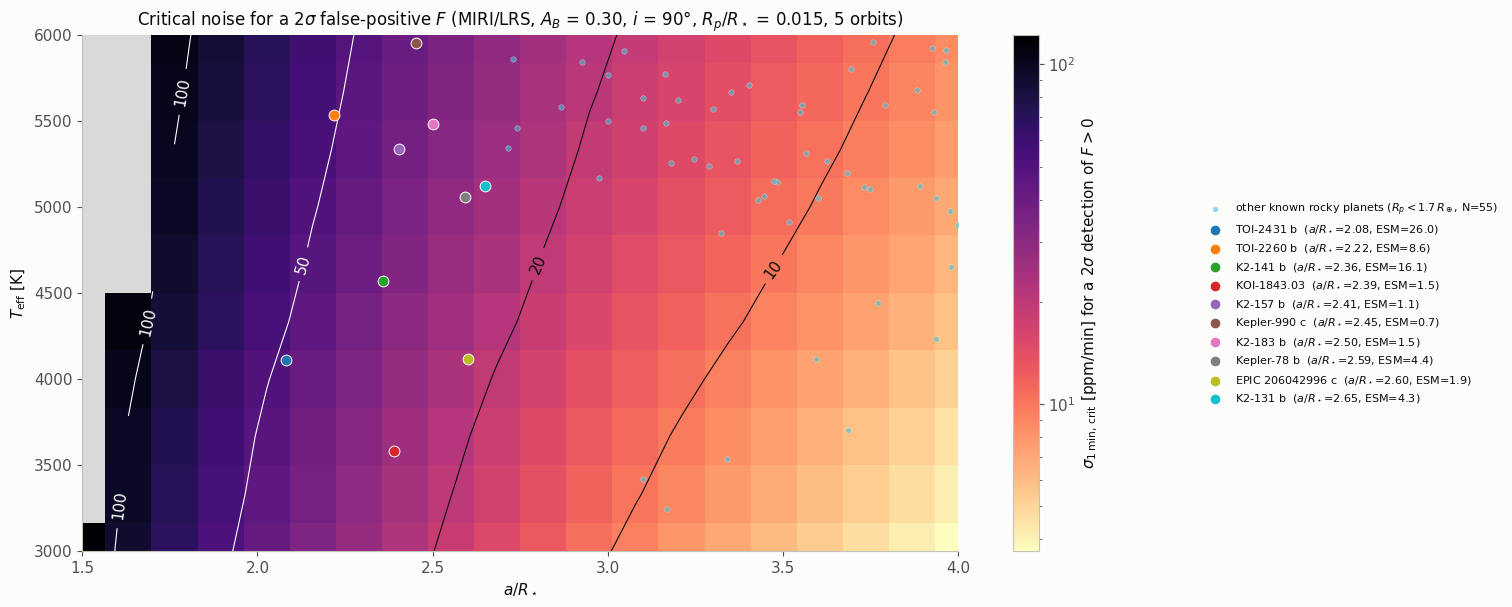

fitted F: max |difference| to the 2.1 map = 0.00e+00


In [15]:
PAPER_MODE = False
# Likelihood-ratio statistic of the spurious F per map cell: dchi2_F = chi2(A_B-only fit) - chi2(joint fit). Cells in parallel; same cost as the 2.1 map plus the A_B-only fit.
z_false = 2.   # the false positive's significance [sigma] that the critical noise refers to
dchi2_map_FT, F_map_FT = false_F_map_grid(cfg, A_B_true, a_rs_grid, T_eff_grid, "T_s", **kw)
sig_crit_FT = plot_false_F_map(a_rs_grid, T_eff_grid, dchi2_map_FT, cfg, AGG, "st_teff", r"$T_{\rm eff}$ [K]", rp_rs_of=lambda y: np.full_like(y, rp_rs_ref), incl=incl_ref, z=z_false, target=target,
                               title=rf"Critical noise for a {z_false:g}$\sigma$ false-positive $F$ ({instrument}, {geom}, $R_p/R_\star$ = {rp_rs_ref:g}, {cfg.n_orbits} orbits)")
paper_figure("falseF_map_teff", PAPER_MODE)   # plot_false_F_map returns sig_crit, the figure is the current one
plt.show()
print(f"fitted F: max |difference| to the 2.1 map = {np.nanmax(np.abs(F_map_FT - F_map_JT)):.2e}")

### 2.6 Per-planet and per-instrument false positives: the spurious $F$ at each planet's own geometry and noise
The map of 2.5 holds $R_p/R_\star$ and $i$ fixed. Here the two fits are repeated for the 10 planets of 2.2 at their **own** geometry and PandExo noise (first cell), and for `retrieval_planet` on the instruments of 1.3, including the joint NRS1 + NRS2 fit (second cell). Per row: the expected significance $z_F = \sqrt{\Delta\chi^2_F}$ of the spurious $F$ with the notebook's `n_orbits`, the verdict against the threshold `z_false`, and three readings of the same number: the **noise margin** $z_F / z$ (the factor by which the noise may be worse, or must be better, for a $z\sigma$ false positive; this is the one that also applies to the joint fit, where all detectors scale alike), the critical noise $\sigma_{1\,\rm min,\,crit}$, and the critical observing time $t_{\rm crit} = t_{\rm obs}\,(z/z_F)^2$. The implied nightside temperature is what the false positive would be reported as: $T_{\rm night}$ of the fitted $(A_B, F)$ from Kreidberg & Loeb eq. 1, for a planet whose true nightside is at the temperature floor.

What to look for: which planets and instruments cross the threshold already at `n_orbits`, and how far the others are from it ($t_{\rm crit}$ in hours of JWST time). Compare the planets' own critical noise with the map value at their position in 2.5: the difference is the $(R_p/R_\star)^2$ scaling and the inclination. Among the instruments, the joint NRS1 + NRS2 fit should be the strongest false positive, since it combines the two arrays' constraints on the same spurious $F$.

This is a hypothesis test: "The spurious F is a 1.5σ effect" therefore means: a fit of this model to data of this quality would reject F = 0 at the p-value that corresponds to 1.5 Gaussian σ, although the planet has no nightside redistribution.

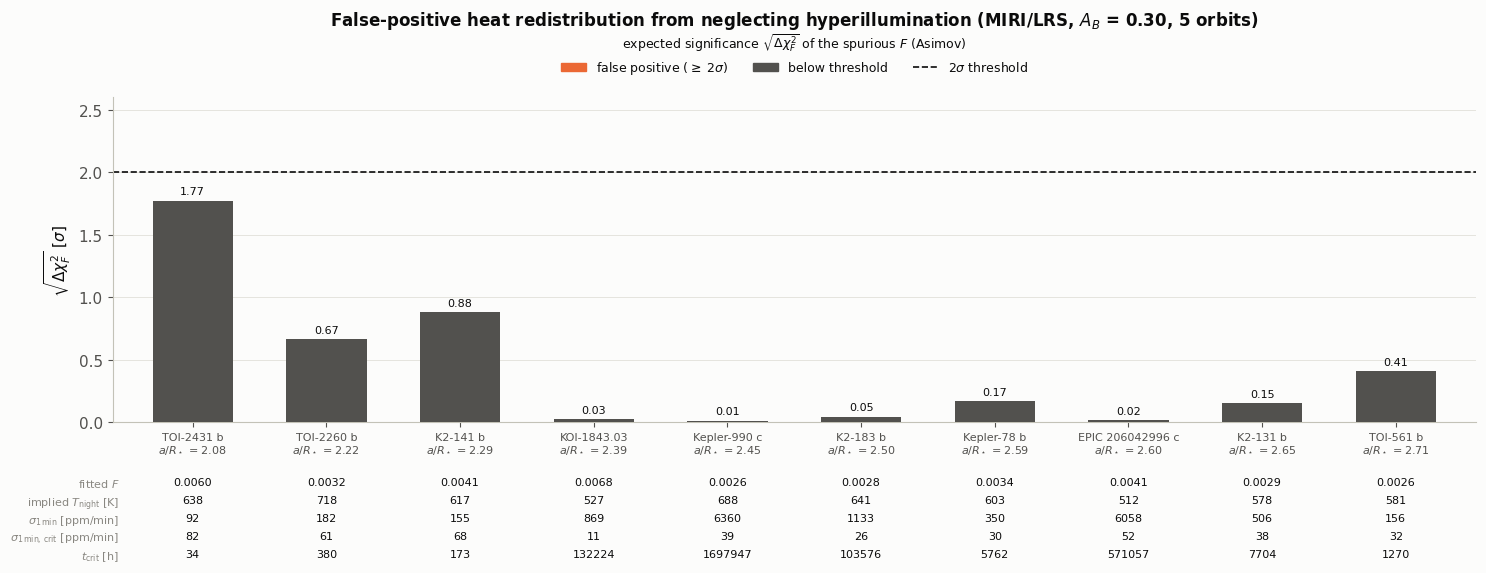

0 of 10 false positive: -
10 of 10 below threshold: TOI-2431 b, TOI-2260 b, K2-141 b, KOI-1843.03, Kepler-990 c, K2-183 b, Kepler-78 b, EPIC 206042996 c, K2-131 b, TOI-561 b
            name  a_rs    esm  A_B_fit_naive  A_B_fit    F_fit  T_night_fit   dchi2_F     z_F  sigma_1min  sigma_1min_crit  noise_margin  t_obs    t_crit         verdict
      TOI-2431 b 2.081  25.96         0.2488   0.1578 0.005978          638     3.149   1.775        91.9            81.54        0.8873   26.9     34.17 below threshold
      TOI-2260 b 2.219  8.632         0.2339   0.1377 0.003227        717.5     0.445  0.6671         182            60.69        0.3336   42.3     380.2 below threshold
        K2-141 b 2.292  16.12         0.2457   0.1686 0.004099        617.2    0.7789  0.8826       154.5            68.19        0.4413  33.64     172.7 below threshold
     KOI-1843.03 2.389   1.47         0.2789   0.2107  0.00678        527.4 0.0006422 0.02534       868.8            11.01       0.01267  21.23 1.

In [16]:
PAPER_MODE = False
# The 10 planets of 2.2 at their own geometry and PandExo noise (sigma10): both fits, dchi2_F and the decision columns. Same cost as 2.2.
tab_FP = planet_false_F_table(cfg, A_B_true, planets10, sigma10, z=z_false, AGG=AGG, **kw)
fig, ax = plot_false_F_bars(tab_FP, title=f"False-positive heat redistribution from neglecting hyperillumination ({instrument}, $A_B$ = {A_B_true:.2f}, {cfg.n_orbits} orbits)")
paper_figure("falseF_bars_planets", PAPER_MODE, fig=fig, tight=False)   # plot_false_F_bars places the parameter rows with subplots_adjust
plt.show()
for v in (FALSE_POSITIVE, NO_FALSE_POSITIVE):
    sel = tab_FP[tab_FP.verdict == v]
    print(f"{len(sel)} of {len(tab_FP)} {v}: {', '.join(sel.name) if len(sel) else '-'}")
print(tab_FP[["name", "a_rs", "esm", "A_B_fit_naive", "A_B_fit", "F_fit", "T_night_fit", "dchi2_F", "z_F", "sigma_1min", "sigma_1min_crit", "noise_margin", "t_obs", "t_crit", "verdict"]]
      .to_string(index=False, float_format=lambda v: f"{v:.4g}"))

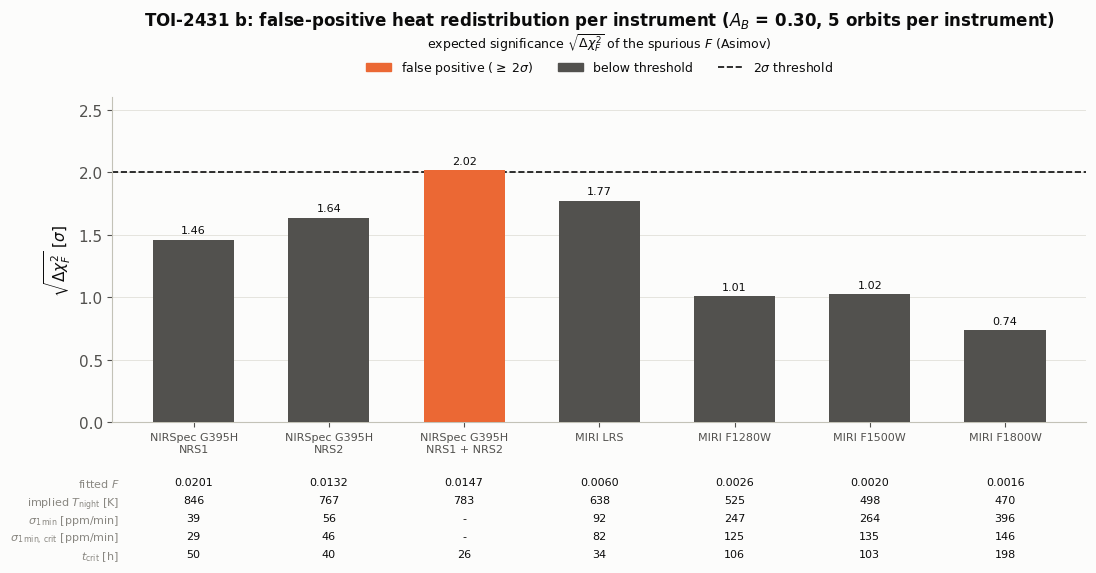

                                     instrument  A_B_fit_naive  A_B_fit    F_fit  T_night_fit  dchi2_F    z_F  sigma_1min  sigma_1min_crit  noise_margin  t_crit         verdict
                        JWST_NIRSpec.G395H_NRS1         0.2677   0.2222  0.02005        846.4    2.134  1.461       39.24            28.66        0.7304   50.43 below threshold
                        JWST_NIRSpec.G395H_NRS2         0.2598   0.2026  0.01321        767.3     2.68  1.637        56.2               46        0.8186   40.15 below threshold
JWST_NIRSpec.G395H_NRS1+JWST_NIRSpec.G395H_NRS2         0.2649   0.2228  0.01471        783.3    4.078  2.019           -                -          1.01   26.39  false positive
                                       MIRI/LRS         0.2488   0.1578 0.005978          638    3.149  1.775        91.9            81.54        0.8873   34.17 below threshold
                                    MIRI/F1280W          0.242   0.1014 0.002576        525.4    1.018  1.009      

In [17]:
PAPER_MODE = False
# retrieval_planet on the instruments of 1.3 (same noise levels, sigma_inst), including the joint NRS1 + NRS2 fit.
tab_FP_inst = instrument_false_F(cfg, retrieval_planet, retrieval_instruments, A_B_inj, z=z_false, sigma_1min=sigma_inst, **kw)
fig, ax = plot_false_F_bars(tab_FP_inst, title=f"{retrieval_planet.name}: false-positive heat redistribution per instrument ($A_B$ = {A_B_inj:.2f}, {cfg.n_orbits} orbits per instrument)")
paper_figure(f"falseF_bars_instruments_{retrieval_planet.name.replace(' ', '')}", PAPER_MODE, fig=fig, tight=False)
plt.show()
print(tab_FP_inst[["instrument", "A_B_fit_naive", "A_B_fit", "F_fit", "T_night_fit", "dchi2_F", "z_F", "sigma_1min", "sigma_1min_crit", "noise_margin", "t_crit", "verdict"]]
      .to_string(index=False, na_rep="-", float_format=lambda v: f"{v:.4g}"))